In [1]:
%load_ext autoreload
%autoreload 2
import sys, os
sys.path.insert(0, '/data/visitor/ma6721/id03/20251117/SCRIPTS/packages')
import config
paths = config.configure_paths()
config.configure_plots()
s = config.Snippets()

In [2]:
# Now all imports should work as normal, example:
import h5py, hdf5plugin
import pandas as pd
import scipy.ndimage
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import numpy as np
import darling
import crispy

In [3]:
file = 'Al1050_green_sample_Nov2025_export.h5'
gmap = crispy.GrainMap( os.path.join(paths.processed, 'DCT', file,) )

In [4]:
gmap.colorize(ipf_axes = np.eye(3))

In [5]:
labels = gmap.labels[gmap.labels.shape[0]//2, ...]
rgb = np.zeros((*labels.shape, 3))
for label in np.unique(labels):
    rgb[label==labels] = gmap.grains[label].rgb[:,2]
rgb[labels==-1]=0

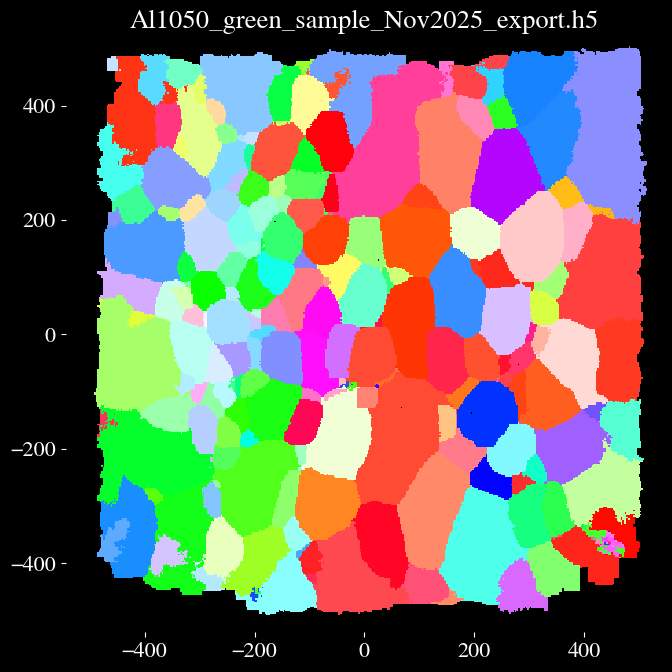

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(7,7))
im = ax.pcolormesh(gmap.X[gmap.labels.shape[0]//2, ...], gmap.Y[gmap.labels.shape[0]//2, ...], rgb)
ax.set_title(file)
plt.tight_layout()
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

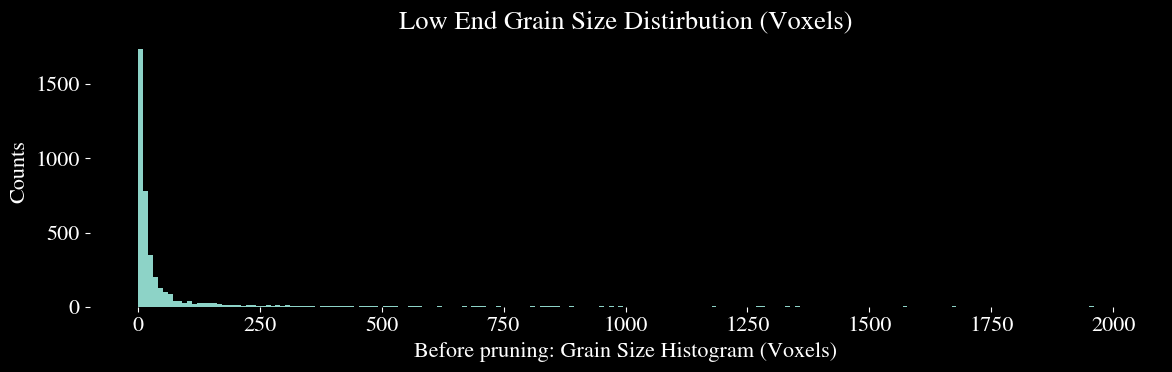

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.hist(gmap.grain_sizes, bins=np.linspace(1, 2000, 200))
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel('Before pruning: Grain Size Histogram (Voxels)')
ax.set_ylabel('Counts')
ax.set_title('Low End Grain Size Distirbution (Voxels)')
plt.tight_layout()
plt.show()

In [8]:
#here we rempove the grain in the boundary (xy) and we remove the smaller grains 
gmap.filter(1000)
gmap.prune_boundary_grains('xy')

In [9]:
gmap.rotate( np.radians(90) * np.array([1, 0, 0]) )

In [10]:
gmap.colorize(ipf_axes = np.eye(3))

In [11]:
#create the image to plot 
labels = gmap.labels[gmap.labels.shape[0]//2, ...]
rgb = np.zeros((*labels.shape, 3))
for label in np.unique(labels):
    m = label==labels
    rgb[m] = gmap.grains[label].rgb[:,1]
rgb[labels==-1]=0

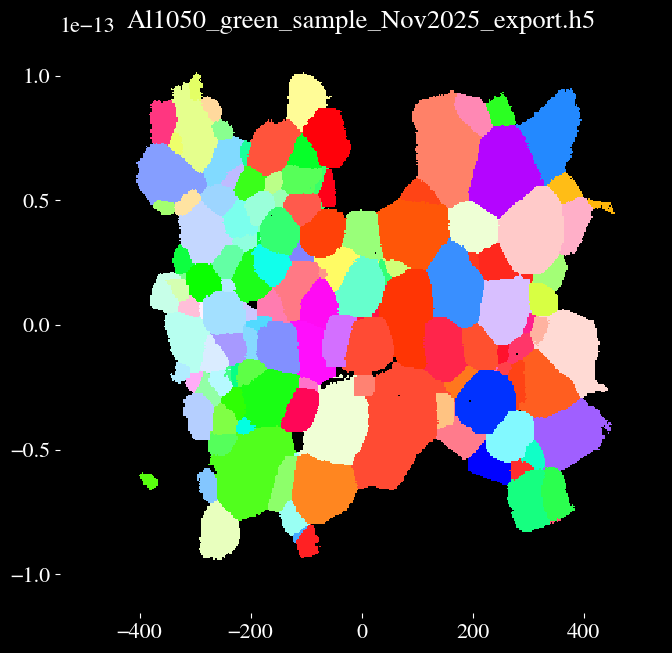

In [12]:
plt.style.use('dark_background')
fig, ax = plt.subplots(1, 1, figsize=(7,7))
im = ax.pcolormesh(gmap.X[gmap.labels.shape[0]//2, ...], gmap.Y[gmap.labels.shape[0]//2, ...], rgb)
ax.set_title(file)
plt.tight_layout()
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

In [13]:
#define the motor ranges of the microscope
motor_bounds = {
    "mu": (0, 17),
    "omega": (-25, 25), # felix has 
    "chi": (-6, 6),
    "phi": (-6, 6),
    "detector_z": (-0.04, 1.96),
    "detector_y": (-0.169, 1.16),
}

goni = crispy.dfxm.Goniometer(
    gmap,
    energy=17,
    detector_distance=3.5,
    motor_bounds=motor_bounds,
    eta=-90,
)

print('Number of grains: ', gmap.number_of_grains)

Number of grains:  654


In [14]:
th_max = np.degrees(
            np.arctan(goni.motor_bounds["detector_y"][1] / goni.detector_distance) / 2.0
        )
def barstring(hkl):
    s = ''
    for h in hkl:
        if h<0:
            s += str(int(h))
        else:
            s += ' ' + str(int(h))
    return s

print(f'Maximum reachable theta = {th_max} ' )
Q = gmap.grains[0].ub @ goni._get_hkls()
for q, hkl in zip(Q.T, goni._get_hkls().T):
    theta = np.degrees(np.arcsin( goni.wavelength /  (2 / np.linalg.norm(q) )))
    if theta < th_max : print(f"    hkl  {barstring(hkl)}  -- @ theta = {np.round(theta, 3)} deg")
    else: print(f"    hkl  {barstring(hkl)}  -- unreachable!!")

Maximum reachable theta = 9.168335712213574 
    hkl  -1-1-1  -- @ theta = 8.973 deg
    hkl  -1-1 1  -- @ theta = 8.973 deg
    hkl   1-1-1  -- @ theta = 8.973 deg
    hkl   1-1 1  -- @ theta = 8.973 deg
    hkl  -1 1-1  -- @ theta = 8.973 deg
    hkl  -1 1 1  -- @ theta = 8.973 deg
    hkl   1 1-1  -- @ theta = 8.973 deg
    hkl   1 1 1  -- @ theta = 8.973 deg
    hkl   0 0-2  -- unreachable!!
    hkl   0-2 0  -- unreachable!!
    hkl  -2 0 0  -- unreachable!!
    hkl   2 0 0  -- unreachable!!
    hkl   0 2 0  -- unreachable!!
    hkl   0 0 2  -- unreachable!!


In [15]:
goni.find_reflections(    
    alignment_tol=0.1, # how close must they be aligned to be included
    maxiter=4000, # how long the optimizer will run
    maxls=25,
    ftol=1e-12,
    mask_unreachable=True,)
df = goni.table_of_reflections()
print(' Total number of found reflections : {} '.format(df.shape[0]))

 Total number of found reflections : 112 


In [16]:
pd.set_option('display.max_rows', None)
df.round(3)

,grain id,h,k,l,mu [dgr],omega [dgr],chi [dgr],phi [dgr],2 theta [dgr],eta [dgr],detector_z [mm]
0,5.0,-1.0,-1.0,-1.0,12.150,-8.416,3.019,-4.673,17.946,-90.0,1133.572
1,23.0,0.0,0.0,-2.0,0.000,-24.907,6.000,3.799,20.751,-90.0,1326.092
2,26.0,0.0,0.0,-2.0,0.000,0.144,4.320,6.000,20.751,-90.0,1326.092
3,27.0,0.0,0.0,-2.0,6.694,-5.432,0.709,1.205,20.751,-90.0,1326.092
4,32.0,0.0,0.0,-2.0,8.505,4.887,0.183,-1.864,20.751,-90.0,1326.092
5,33.0,-1.0,1.0,-1.0,7.123,3.649,3.439,0.257,17.946,-90.0,1133.572
6,34.0,0.0,0.0,-2.0,1.630,-4.574,2.451,5.760,20.751,-90.0,1326.092
7,42.0,0.0,0.0,-2.0,17.000,25.000,1.493,-4.386,20.751,-90.0,1326.092
8,44.0,-1.0,-1.0,-1.0,5.415,-16.418,4.307,2.850,17.946,-90.0,1133.572
9,52.0,0.0,0.0,-2.0,9.118,13.581,0.352,-1.053,20.751,-90.0,1326.092


In [17]:
pc=gmap

In [18]:
gmap.texturize()

In [19]:
for i, g in enumerate(pc.grains):
    g.id = i

In [20]:
rgb = np.array([g.rgb.flatten() for g in gmap.grains])

In [21]:
rgb.shape

(654, 9)

In [22]:
ii = 0
for g in gmap.grains:
    ii += 1 if g.dfxm is not None else 0
print(f"Total number of grains after filtering is {len(gmap.grains)}, out of these {ii} grains have accessible reflections.")

Total number of grains after filtering is 654, out of these 112 grains have accessible reflections.


In [23]:
# filter neighbours by reflections such that only grains with reflections are considered
lab_axis = np.array([0, 1, 0])

pc.colorize(ipf_axes=np.array([[0, 1, 0]]))

prefered_hkl_along_lab_axis = np.array([
    [1, 1, 1], 
    [-1, -1, -1],
    [-1, 1, 1], 
    [1, -1, 1],
    [1, 1, -1],
    [1, -1, -1],
    [-1, -1, 1],
    [-1, 1, -1],
]).T

print(prefered_hkl_along_lab_axis.shape)
alignment_threshold = 15
min_grains_in_cluster = 3
min_misorientation = 20

# filters clusters with at least 3 diffracting grains where at least grains are blue
# moreover at least 2 neighbours to the central grain must have a 15 degree misorientation
# to the central grain

def row_style(row):
    rgb = (pc.grains[row.ID].rgb.flatten()*255).astype(int)
    colorhex = '#%02x%02x%02x' % tuple(rgb)
    return pd.Series(f'background-color: {colorhex}', row.index)

stylers = []
clusters = []
rgbs = []

wedges = []
all_wedges = []
for i, g in enumerate(pc.grains):

    Q = g.ub @ prefered_hkl_along_lab_axis
    qhat = Q / np.linalg.norm(Q, axis=0)
    wedge = np.abs(np.min( np.degrees( np.arccos( qhat.T @ lab_axis ) ) ))
    all_wedges.append(wedge)


    if g.dfxm is not None and wedge < alignment_threshold:
        neighbours = pc.grains[pc.neighbours[i]]

        has_reflection = np.array( [_g.dfxm is not None for _g in neighbours] )

        if len(has_reflection)==0:
            clusters.append( [] )
            continue

        misorientations = pc.misorientations[i][ has_reflection ]
        
        nwedges = [  ]
        for ng in neighbours[has_reflection]:
            Q = ng.ub @ prefered_hkl_along_lab_axis
            qhat = Q / np.linalg.norm(Q, axis=0)
            nwedges.append( np.abs(np.min( np.degrees( np.arccos( qhat.T @ lab_axis ) ) )) )
        #nwedges = np.abs(np.sort( np.array() )[0:2])
        nwedges = np.sort(nwedges)[0:2]

        if np.sum(has_reflection)>min_grains_in_cluster - 1 and np.min(np.sort(misorientations)[-2:])>min_misorientation and np.all(nwedges<alignment_threshold):

            data = []
            data.append( [i]+ list(np.round( (g.ubi @ lab_axis)/np.linalg.norm(g.ubi @ lab_axis), 2)) )

            clusters.append( [g.id] )
            for ii, gg in zip(pc.neighbours[i][has_reflection], neighbours[has_reflection] ):
                data.append( [ii] + list(np.round( (gg.ubi @ lab_axis) / np.linalg.norm(gg.ubi @ lab_axis), 2)) )
                clusters[-1].append(gg.id)
            df = pd.DataFrame( data, columns = ['ID', 'h', 'k', 'l'])
            styler = df.style.apply(row_style, axis=1, subset=['ID']).format(precision=2)
            stylers.append(styler)
            rgbs.append( pc.grains[int(df.to_numpy()[0,0])].rgb.flatten() )
            wedges.append(wedge)

        else:
            clusters.append( [] )
    else:
        clusters.append( [] )


print(' ---- Total number of candidate grain clusters for DFXM is {} ----- '.format(len(stylers)))
print('')

all_wedges = np.array(all_wedges)
index = np.argsort( wedges )


for i in index:
    display( stylers[i] )
    print('')

(3, 8)
 ---- Total number of candidate grain clusters for DFXM is 1 ----- 



,ID,h,k,l
0,210,-0.49,-0.58,-0.65
1,159,-0.27,-0.57,-0.78
2,196,0.26,0.07,-0.96
3,317,0.58,-0.58,-0.58
4,349,0.61,-0.51,-0.61


In [43]:
clusters[210]

[210, 159, 196, 317, 349]

In [40]:
cluster_index = 210
gmap.write(file + f"_cluster_{cluster_index}.xdmf", 
           clusters[cluster_index])

In [ ]:
gmap.X

In [ ]:
pc.neighbours[210]

In [ ]:
pc.misorientations[210]

In [ ]:
pc.interface_areas[210]

In [ ]:
pc.grains[210].dfxm

In [279]:
pc.grain_sizes[210]

31549

In [280]:
pc.grain_sizes[pc.neighbours[210]] 

array([ 4204,  2670,  4048, 87711, 28667,  6709, 21934,  8585, 65916,
       42975, 27063], dtype=uint32)

In [ ]:
pc.labels.shape

In [ ]:
gmap??

In [ ]:
#2130 and 2219 48 degrees misoriented, 795 interface area, the 2130 is close to 0.5 0.5 0.7 and 2219 is close to 1 0 0
#1990 and 2130, 39 degrees misoriented, 707 interface area, the 1990 is close to 1 1 0, and 2130 is 0.5 0.5 0.7 

In [ ]:
pd.set_option('display.max_rows', None)
df.round(3)